# Mammalian cell cycle

This notebook reproduces the analysis of the cell cycle model of the [MaBoSS website](https://maboss.curie.fr).

The model is based on a published Boolean model of the mammalian cell cycle
([Fauré et al., 2006](https://doi.org/10.1093/bioinformatics/btl210)). It describes the signaling network
that controls the mammalian cell cycle. Mutants can be simulated with the parameters `$CycD_del`, `$Cdc20_del`
and `$Rb_del`: they are set to 0 for the wild type, and to 1 to simulate the corresponding deletion.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `cellcycle.bnd`,
`cellcycle_runcfg.cfg` and `cellcycle_runcfg_randinit.cfg`, in the same folder as this notebook.

In [1]:
import os
import maboss
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Common style for the figures of the MaBoSS website notebooks
COLORS = ["#FF7F00", "#1F77B4", "#2CA02C", "#D62728", "#9467BD",
          "#8C564B", "#E377C2", "#17BECF", "#BCBD22", "#7F7F7F"]
mpl.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.prop_cycle": mpl.cycler(color=COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "legend.frameon": False,
    "lines.linewidth": 2,
})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    """Save a figure in the figures folder."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"))

def state_label(state):
    """Readable label for a MaBoSS state."""
    return "none active" if state == "<nil>" else state.replace(" -- ", ", ")

def pie(probas, ax, title=None, min_proba=0.01, labels=None):
    """Pie chart of a distribution; probabilities below min_proba are grouped as 'others'."""
    probas = pd.Series(probas).sort_values(ascending=False)
    small = probas[probas < min_proba]
    probas = probas[probas >= min_proba]
    if len(small) > 0:
        probas["others"] = small.sum()
    names = [labels.get(s, state_label(s)) if labels else state_label(s) for s in probas.index]
    colors = [COLORS[i % len(COLORS)] if s != "others" else "#D9D9D9" for i, s in enumerate(probas.index)]
    wedges, _ = ax.pie(probas.values, colors=colors, startangle=90, counterclock=False,
                       wedgeprops={"linewidth": 1, "edgecolor": "white"})
    ax.legend(wedges, [f"{n} ({p:.1%})" for n, p in zip(names, probas.values)],
              loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_aspect("equal")
    if title:
        ax.set_title(title)

def set_refstate_all(sim, value=0):
    """Give a reference state to every node.

    With MaBoSS 2.6.6, the states of the stationary distributions only include the nodes
    having a reference state; this makes them include all the nodes, as in previous versions.
    """
    for node in sim.network:
        if node not in sim.refstate:
            sim.refstate[node] = value

ipylab module is not installed, menus and toolbar are disabled.


## The model

In [2]:
sim = maboss.load("cellcycle.bnd", "cellcycle_runcfg.cfg")
sim.print_bnd()

Node CycD {

	logic = CycD;
	rate_up = (NOT $CycD_del) ? 0.0 : 0.0;
	rate_down = $CycD_del ? $fast : 0.0;
}
Node CycE {

	logic = !Rb & E2F;
	rate_up = @logic ? $slow : 0.0;
	rate_down = @logic ? 0.0 : $fast;
}

Node CycA {

	logic = !Rb & !Cdc20 & !(UbcH10 & cdh1) & (CycA | E2F);
	rate_up = @logic ? $slow : 0.0;
	rate_down = @logic ? 0.0 : $fast;
}

Node CycB {

	logic = !Cdc20 & !cdh1;
	rate_up = @logic ? $slow : 0.0;
	rate_down = @logic ? 0.0 : $fast;
}

Node Rb {

	logic = !CycD & !CycB & (p27 | !(CycA | CycE));
	rate_up = (@logic AND (NOT $Rb_del)) ? $fast : 0.0;
	rate_down = (@logic AND (NOT $Rb_del)) ? 0.0 : $fast;
}

Node E2F {

	logic = !Rb & !CycB & (!CycA | p27);
	rate_up = @logic ? $slow : 0.0;
	rate_down = @logic ? 0.0 : $fast;
}

Node p27 {

	logic = !CycD & !CycB & (!(CycA | CycE) | (p27 & !(CycE & CycA)));
	rate_up = @logic ? $fast : 0.0;
	rate_down = @logic ? 0.0 : $fast;
}

Node Cdc20 {

	logic = CycB;
	rate_up = (@logic AND (NOT $Cdc20_del)) ? $slow : 0.0;
	rate_down

## Dynamics from the start of the cell cycle

The first configuration file sets the initial condition corresponding to the start of the cell cycle
(CycD, Rb, p27 and cdh1 active). The configuration files use the physical random generator: we use instead
the pseudo-random generator, with a fixed seed, to make the results reproducible, and 4 threads.

In [3]:
sim.update_parameters(use_physrandgen=0, thread_count=4)
result = sim.run()

We plot the probabilities of the active cyclins, together with the entropy and the transition entropy.

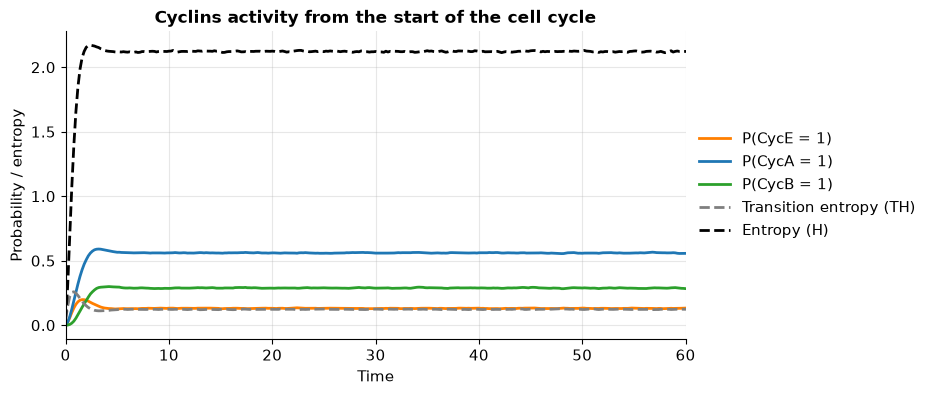

In [4]:
nodes = result.get_nodes_probtraj()
entropy = result.get_entropy_trajectory()

fig, ax = plt.subplots(figsize=(8, 4))
for cyclin in ["CycE", "CycA", "CycB"]:
    ax.plot(nodes.index, nodes[cyclin], label=f"P({cyclin} = 1)")
ax.plot(entropy.index, entropy["TH"], "--", color="#7F7F7F", label="Transition entropy (TH)")
ax.plot(entropy.index, entropy["H"], "--", color="black", label="Entropy (H)")
ax.set_xlim(0, 60)
ax.set_xlabel("Time")
ax.set_ylabel("Probability / entropy")
ax.set_title("Cyclins activity from the start of the cell cycle")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
save(fig, "cellcycle_cyclins")

## Stationary distributions, from a random initial condition

The second configuration file uses a random initial condition, to study the stationary distributions.

*Note:* with MaBoSS 2.6.6, the states of the stationary distributions only include the nodes having a
reference state. We give a reference state to every node, so that the stationary distributions are
described with all the nodes (this does not change the simulation).

In [5]:
sim_random = maboss.load("cellcycle.bnd", "cellcycle_runcfg_randinit.cfg")
sim_random.update_parameters(use_physrandgen=0, thread_count=4)
set_refstate_all(sim_random)
result_random = sim_random.run()

clusters = result_random.get_statdist_clusters()
summary = result_random.get_statdist_clusters_summary()

The simulation produces two clusters, which represent two indecomposable stationary distributions.
We name them according to their content: a stationary distribution concentrated on a single state is a
fixed point.

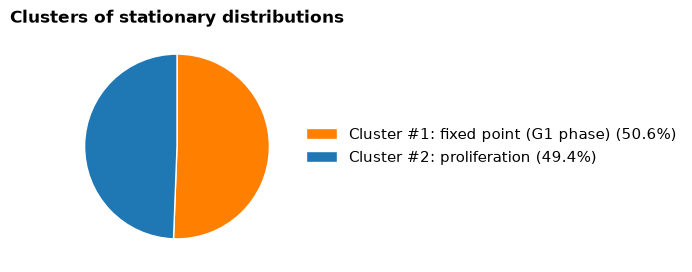

In [6]:
sizes = pd.Series({name: len(cluster) for name, cluster in zip(summary.index, clusters)})
distributions = {name: summary.loc[name].dropna() for name in summary.index}

names = {}
for name, distribution in distributions.items():
    if distribution.max() > 0.95:
        names[name] = f"Cluster {name}: fixed point (G1 phase)"
    else:
        names[name] = f"Cluster {name}: proliferation"

fig, ax = plt.subplots(figsize=(5, 3))
pie(sizes / sizes.sum(), ax, "Clusters of stationary distributions", labels=names)
save(fig, "cellcycle_clusters")

The proliferation cluster can be interpreted as a desynchronized proliferating cell population,
while the fixed point represents the G1 phase.

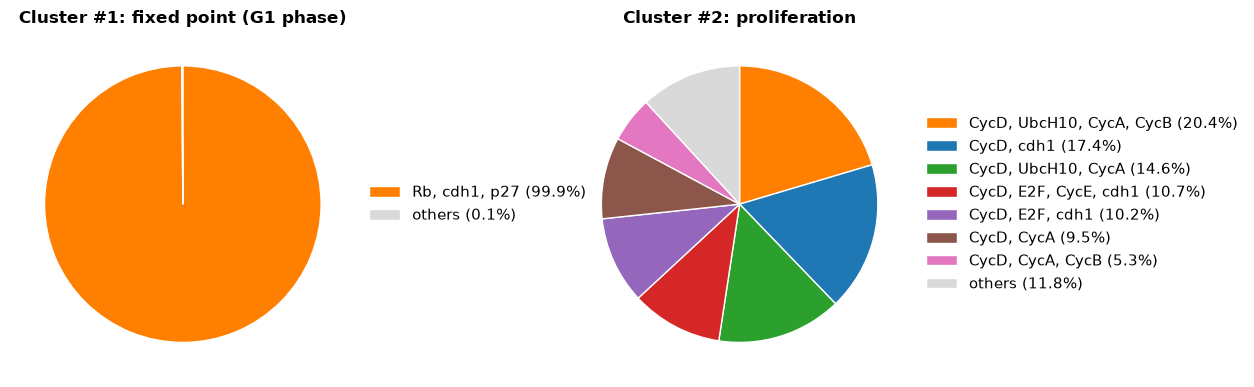

In [7]:
fig, axes = plt.subplots(1, len(distributions), figsize=(13, 4))
for ax, (name, distribution) in zip(axes, distributions.items()):
    pie(distribution, ax, names[name], min_proba=0.02)
fig.tight_layout()
save(fig, "cellcycle_stationary_distributions")